In [2]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    silhouette_score
)

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [3]:
np.random.seed(42)

n = 1000

locations = ['Hostel', 'Market', 'Residential', 'College', 'Hospital']
days = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

data = []

for i in range(n):
    location = np.random.choice(locations)
    day = np.random.choice(days)

    temperature = np.random.randint(20, 41)

    # Different locations have different waste generation rates
    population_map = {
        'Hostel': 500,
        'Market': 1200,
        'Residential': 800,
        'College': 1500,
        'Hospital': 1000
    }

    population = population_map[location]

    # Weekend waste generation is generally higher
    weekend_factor = 1.2 if day in ['Saturday', 'Sunday'] else 1.0

    # Location-based waste generation
    location_factor = {
        'Hostel': 0.6,
        'Market': 0.9,
        'Residential': 0.5,
        'College': 0.7,
        'Hospital': 0.8
    }

    base_waste = location_factor[location] * 70

    waste_level = (
        base_waste * weekend_factor
        + temperature * 0.3
        + np.random.normal(0, 8)
    )

    waste_level = np.clip(waste_level, 0, 100)

    data.append([
        f'B{i+1}',
        location,
        day,
        temperature,
        population,
        round(waste_level, 2)
    ])

df = pd.DataFrame(data, columns=[
    'Bin_ID',
    'Location',
    'Day',
    'Temperature',
    'Population',
    'Waste_Level'
])

df.head()

,Bin_ID,Location,Day,Temperature,Population,Waste_Level
0,B1,College,Friday,34,1500,64.38
1,B2,Market,Wednesday,30,1200,84.18
2,B3,Residential,Friday,23,800,45.04
3,B4,Hospital,Tuesday,31,1000,57.87
4,B5,Market,Thursday,40,1200,86.70


In [4]:
df.to_csv('../dataset/waste_management.csv', index=False)

print("Dataset saved successfully!")
print("Total Records:", len(df))

Dataset saved successfully!
Total Records: 1000


In [5]:
print("First 5 Records:")
display(df.head())

print("\nDataset Shape:")
print(df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

First 5 Records:


,Bin_ID,Location,Day,Temperature,Population,Waste_Level
0,B1,College,Friday,34,1500,64.38
1,B2,Market,Wednesday,30,1200,84.18
2,B3,Residential,Friday,23,800,45.04
3,B4,Hospital,Tuesday,31,1000,57.87
4,B5,Market,Thursday,40,1200,86.70



Dataset Shape:
(1000, 6)

Column Names:
['Bin_ID', 'Location', 'Day', 'Temperature', 'Population', 'Waste_Level']


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Bin_ID       1000 non-null   str    
 1   Location     1000 non-null   str    
 2   Day          1000 non-null   str    
 3   Temperature  1000 non-null   int64  
 4   Population   1000 non-null   int64  
 5   Waste_Level  1000 non-null   float64
dtypes: float64(1), int64(2), str(3)
memory usage: 65.2 KB


In [7]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
Bin_ID         0
Location       0
Day            0
Temperature    0
Population     0
Waste_Level    0
dtype: int64


In [8]:
print("Duplicate Records:", df.duplicated().sum())

Duplicate Records: 0


In [9]:
df.describe()

,Temperature,Population,Waste_Level
count,1000.000000,1000.000000,1000.000000
mean,29.732000,1008.300000,60.620180
std,6.113227,340.201186,13.872336
min,20.000000,500.000000,21.610000
25%,24.000000,800.000000,51.005000
50%,30.000000,1000.000000,60.330000
75%,35.000000,1200.000000,69.647500
max,40.000000,1500.000000,100.000000


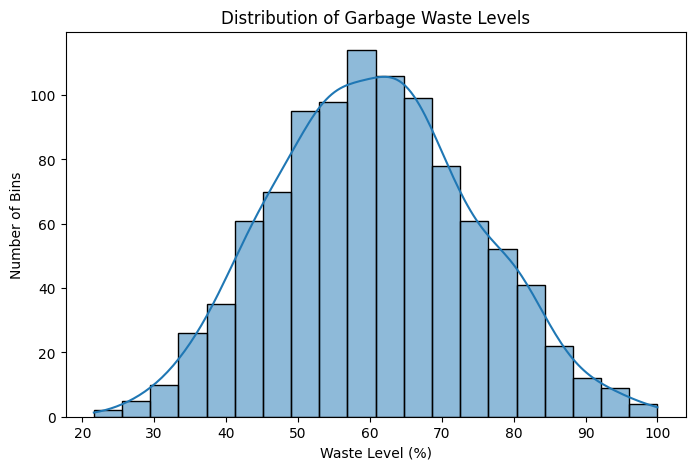

In [10]:
plt.figure(figsize=(8, 5))

sns.histplot(df['Waste_Level'], bins=20, kde=True)

plt.title('Distribution of Garbage Waste Levels')
plt.xlabel('Waste Level (%)')
plt.ylabel('Number of Bins')

plt.show()

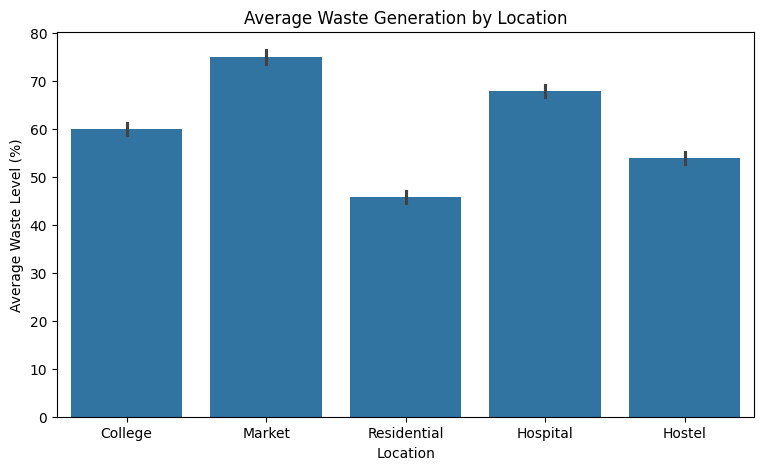

In [11]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Location',
    y='Waste_Level',
    estimator=np.mean
)

plt.title('Average Waste Generation by Location')
plt.xlabel('Location')
plt.ylabel('Average Waste Level (%)')

plt.show()

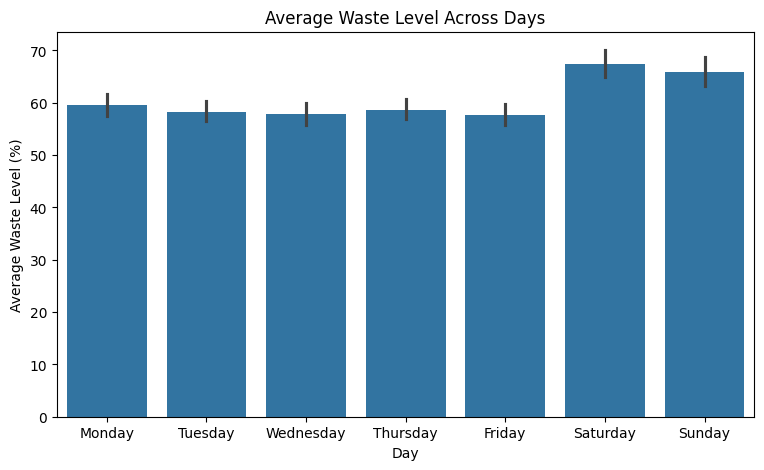

In [12]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='Day',
    y='Waste_Level',
    estimator=np.mean,
    order=days
)

plt.title('Average Waste Level Across Days')
plt.xlabel('Day')
plt.ylabel('Average Waste Level (%)')

plt.show()

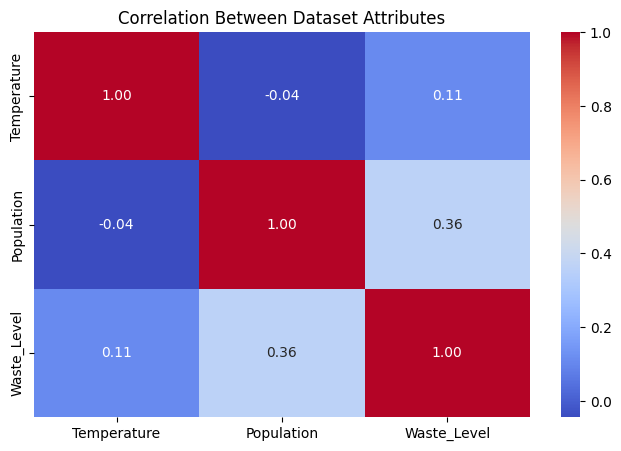

In [13]:
plt.figure(figsize=(8, 5))

numeric_df = df[
    ['Temperature', 'Population', 'Waste_Level']
]

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Dataset Attributes')

plt.show()

In [14]:
def classify_waste(level):

    if level <= 40:
        return 'Low'

    elif level <= 75:
        return 'Medium'

    else:
        return 'High'


df['Waste_Category'] = df['Waste_Level'].apply(classify_waste)

df.head()

,Bin_ID,Location,Day,Temperature,Population,Waste_Level,Waste_Category
0,B1,College,Friday,34,1500,64.38,Medium
1,B2,Market,Wednesday,30,1200,84.18,High
2,B3,Residential,Friday,23,800,45.04,Medium
3,B4,Hospital,Tuesday,31,1000,57.87,Medium
4,B5,Market,Thursday,40,1200,86.70,High


In [15]:
df_encoded = df.copy()

le_location = LabelEncoder()
le_day = LabelEncoder()

df_encoded['Location'] = le_location.fit_transform(
    df_encoded['Location']
)

df_encoded['Day'] = le_day.fit_transform(
    df_encoded['Day']
)

print(df_encoded.head())

  Bin_ID  Location  Day  Temperature  Population  Waste_Level Waste_Category
0     B1         0    0           34        1500        64.38         Medium
1     B2         3    6           30        1200        84.18           High
2     B3         4    0           23         800        45.04         Medium
3     B4         1    5           31        1000        57.87         Medium
4     B5         3    4           40        1200        86.70           High


In [16]:
X = df_encoded[['Location', 'Day', 'Temperature', 'Population']]

y = df_encoded['Waste_Category']

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   Location  Day  Temperature  Population
0         0    0           34        1500
1         3    6           30        1200
2         4    0           23         800
3         1    5           31        1000
4         3    4           40        1200

Target:
0    Medium
1      High
2    Medium
3    Medium
4      High
Name: Waste_Category, dtype: str


In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Records:", len(X_train))
print("Testing Records:", len(X_test))

Training Records: 800
Testing Records: 200


In [18]:
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [19]:
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 73.5 %

Classification Report:
              precision    recall  f1-score   support

        High       0.48      0.38      0.42        32
         Low       0.00      0.00      0.00        13
      Medium       0.80      0.87      0.84       155

    accuracy                           0.73       200
   macro avg       0.43      0.42      0.42       200
weighted avg       0.70      0.73      0.72       200



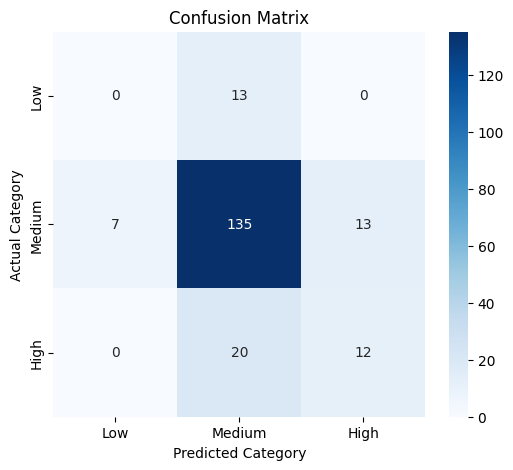

In [20]:
cm = confusion_matrix(y_test, y_pred, labels=['Low', 'Medium', 'High'])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Low', 'Medium', 'High'],
    yticklabels=['Low', 'Medium', 'High']
)

plt.xlabel('Predicted Category')
plt.ylabel('Actual Category')
plt.title('Confusion Matrix')

plt.show()

In [21]:
cluster_data = df[
    ['Temperature', 'Population', 'Waste_Level']
]

scaler = StandardScaler()

scaled_data = scaler.fit_transform(cluster_data)

print("Data prepared for clustering!")

Data prepared for clustering!


In [22]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(scaled_data)

print(df[['Bin_ID', 'Location', 'Waste_Level', 'Cluster']].head(10))

  Bin_ID     Location  Waste_Level  Cluster
0     B1      College        64.38        1
1     B2       Market        84.18        1
2     B3  Residential        45.04        0
3     B4     Hospital        57.87        0
4     B5       Market        86.70        1
5     B6     Hospital        79.11        1
6     B7  Residential        41.69        0
7     B8  Residential        45.39        0
8     B9       Hostel        39.99        0
9    B10       Market        75.91        1


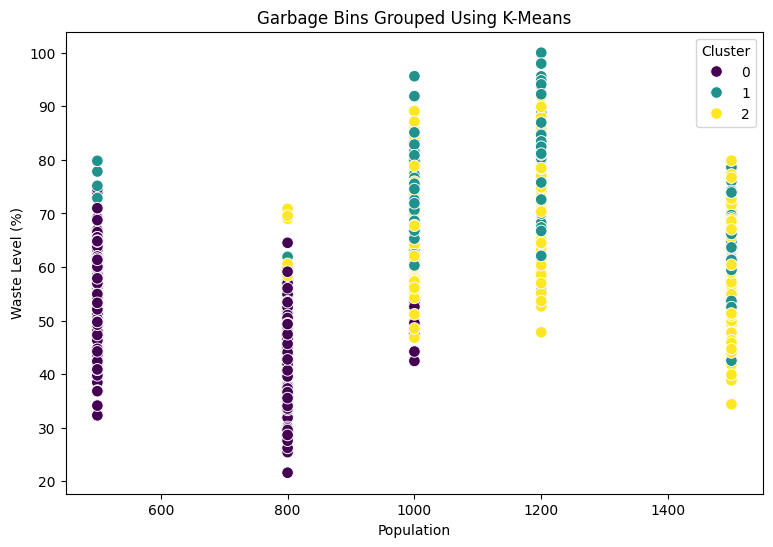

In [23]:
plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x='Population',
    y='Waste_Level',
    hue='Cluster',
    palette='viridis',
    s=70
)

plt.title('Garbage Bins Grouped Using K-Means')
plt.xlabel('Population')
plt.ylabel('Waste Level (%)')

plt.show()

In [24]:
cluster_summary = df.groupby('Cluster').agg(
    Average_Waste=('Waste_Level', 'mean'),
    Average_Population=('Population', 'mean'),
    Total_Bins=('Bin_ID', 'count')
)

print(cluster_summary)

         Average_Waste  Average_Population  Total_Bins
Cluster                                               
0            49.338170          661.597938         388
1            70.867767         1206.666667         300
2            64.796923         1248.717949         312


In [25]:
score = silhouette_score(scaled_data, df['Cluster'])

print("Silhouette Score:", round(score, 3))

Silhouette Score: 0.314


In [26]:
def collection_priority(category):

    if category == 'High':
        return 'URGENT COLLECTION'

    elif category == 'Medium':
        return 'SCHEDULE COLLECTION'

    else:
        return 'NO IMMEDIATE COLLECTION'


df['Collection_Priority'] = df['Waste_Category'].apply(
    collection_priority
)

display(
    df[
        ['Bin_ID', 'Location', 'Waste_Level',
         'Waste_Category', 'Collection_Priority']
    ].head(15)
)

,Bin_ID,Location,Waste_Level,Waste_Category,Collection_Priority
0,B1,College,64.38,Medium,SCHEDULE COLLECTION
1,B2,Market,84.18,High,URGENT COLLECTION
2,B3,Residential,45.04,Medium,SCHEDULE COLLECTION
3,B4,Hospital,57.87,Medium,SCHEDULE COLLECTION
4,B5,Market,86.70,High,URGENT COLLECTION
5,B6,Hospital,79.11,High,URGENT COLLECTION
6,B7,Residential,41.69,Medium,SCHEDULE COLLECTION
7,B8,Residential,45.39,Medium,SCHEDULE COLLECTION
8,B9,Hostel,39.99,Low,NO IMMEDIATE COLLECTION
9,B10,Market,75.91,High,URGENT COLLECTION


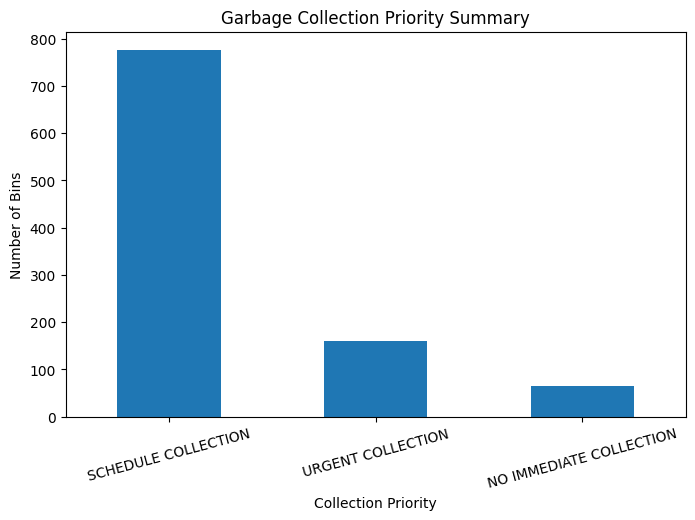

In [27]:
priority_counts = df['Collection_Priority'].value_counts()

plt.figure(figsize=(8, 5))

priority_counts.plot(kind='bar')

plt.title('Garbage Collection Priority Summary')
plt.xlabel('Collection Priority')
plt.ylabel('Number of Bins')

plt.xticks(rotation=15)

plt.show()

In [28]:
new_bin = pd.DataFrame({
    'Location': ['Market'],
    'Day': ['Saturday'],
    'Temperature': [35],
    'Population': [1200]
})

# Encode the categorical values
new_bin['Location'] = le_location.transform(new_bin['Location'])
new_bin['Day'] = le_day.transform(new_bin['Day'])

# Predict category
prediction = model.predict(new_bin)[0]

# Generate recommendation
priority = collection_priority(prediction)

print("SMART WASTE MANAGEMENT SYSTEM")
print("--------------------------------")
print("Location: Market")
print("Day: Saturday")
print("Temperature: 35°C")
print("Population: 1200")

print("\nPredicted Waste Category:", prediction)
print("Collection Priority:", priority)

SMART WASTE MANAGEMENT SYSTEM
--------------------------------
Location: Market
Day: Saturday
Temperature: 35°C
Population: 1200

Predicted Waste Category: High
Collection Priority: URGENT COLLECTION


In [31]:
import joblib

folder = '../models/'

joblib.dump(model, folder + 'waste_classifier.pkl')

joblib.dump(le_location, folder + 'location_encoder.pkl')
joblib.dump(le_day, folder + 'day_encoder.pkl')

joblib.dump(kmeans, folder + 'kmeans_model.pkl')
joblib.dump(scaler, folder + 'scaler.pkl')

df.to_csv('../dataset/waste_management.csv', index=False)

print("Models saved successfully!")

Models saved successfully!
